# **Lab7 - Ensemble Learning**

**Course: Advanced Machine Learning** <br>
**Lecturer: Dr. Sothea HAS**

----

**Objective:**  Ensemble Learning Methods are about combining several base learners to enhance its performance. In this lab, you will apply each ensemble learning method on real datasets and analyze its sensitivity in terms of the key hyperparameters of the method. Moreover, the feature importances will also be computed from each model.


> **The `Jupyter Notebook` for this TP can be downloaded here: [TP7_Ensemble_Learning](https://hassothea.github.io/Advanced-Machine-Learning-ITC/TPs/TP7_Ensemble_Learning.ipynb)**.

-------

## **1. Auto-MPG Dataset**

The dataset is downloaded from [`UCI Machine Learning Repository`](https://archive.ics.uci.edu/dataset/9/auto+mpg){target='_blank'}. The data concerns city-cycle fuel consumption in miles per gallon, to be predicted in terms of 3 multivalued discrete and 5 continuous attributes, (Quinlan, 1993). 

Load the dataset from kaggle using the following link: [`Auto-MPG` dataset](https://www.kaggle.com/datasets/uciml/autompg-dataset){target='_blank'}.

In [6]:
import pandas as pd
import kagglehub

path = kagglehub.dataset_download('uciml/autompg-dataset')
data = pd.read_csv(path + '/auto-mpg.csv')
data.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


In [31]:
len(data['car name'].unique())

301

**A. Overview and Univariate Analysis:**

- Check the dimension of the dataset and modify columns with wrong data type.
- What’s wrong with the column `horsepower`? Properly solve it.
- Perform univariate analysis aiming at understanding individual columns of the data and dectecting the following problems:
    - Outliers
    - Duplications
    - Missing data.

In [7]:
print(data.shape)
data.dtypes

(398, 9)


mpg             float64
cylinders         int64
displacement    float64
horsepower       object
weight            int64
acceleration    float64
model year        int64
origin            int64
car name         object
dtype: object

In [ ]:
# Handling origin
data['origin'] = data['origin'].astype(object)
data.dtypes

mpg             float64
cylinders         int64
displacement    float64
horsepower       object
weight            int64
acceleration    float64
model year        int64
origin           object
car name         object
dtype: object

In [10]:
# Handling 'Horsepower'
# data['horsepower'] = data['horsepower'].astype(int)
data['horsepower'].unique()

array(['130', '165', '150', '140', '198', '220', '215', '225', '190',
       '170', '160', '95', '97', '85', '88', '46', '87', '90', '113',
       '200', '210', '193', '?', '100', '105', '175', '153', '180', '110',
       '72', '86', '70', '76', '65', '69', '60', '80', '54', '208', '155',
       '112', '92', '145', '137', '158', '167', '94', '107', '230', '49',
       '75', '91', '122', '67', '83', '78', '52', '61', '93', '148',
       '129', '96', '71', '98', '115', '53', '81', '79', '120', '152',
       '102', '108', '68', '58', '149', '89', '63', '48', '66', '139',
       '103', '125', '133', '138', '135', '142', '77', '62', '132', '84',
       '64', '74', '116', '82'], dtype=object)

- The column `horsepower` contain a symbol `?` which seems to be the missing data. We shall handle them. 

In [ ]:
# How many percent of the rows are missing
data.query("horsepower == '?'").shape[0]/data.shape[0] * 100

1.507537688442211

- Only 1.5% of the column `horsepower` are missing, therefore we simply drop them.

In [ ]:
data = data.query("horsepower != '?'") # we select only rows without `?`
data['horsepower'] = data['horsepower'].astype(int) # we don't have `?` therefore no more error.
data.dtypes

mpg             float64
cylinders         int64
displacement    float64
horsepower        int64
weight            int64
acceleration    float64
model year        int64
origin           object
car name         object
dtype: object

### Univariate analysis

In [16]:
quan_var = data.select_dtypes(include='number').columns.to_list()
quan_var

['mpg',
 'cylinders',
 'displacement',
 'horsepower',
 'weight',
 'acceleration',
 'model year']

In [17]:
data.describe()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year
count,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000,392.000000
mean,23.445918,5.471939,194.411990,104.469388,2977.584184,15.541327,75.979592
std,7.805007,1.705783,104.644004,38.491160,849.402560,2.758864,3.683737
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
25%,17.000000,4.000000,105.000000,75.000000,2225.250000,13.775000,73.000000
50%,22.750000,4.000000,151.000000,93.500000,2803.500000,15.500000,76.000000
75%,29.000000,8.000000,275.750000,126.000000,3614.750000,17.025000,79.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000


In [18]:
data.query("cylinders == 3")

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
71,19.0,3,70.0,97,2330,13.5,72,3,mazda rx2 coupe
111,18.0,3,70.0,90,2124,13.5,73,3,maxda rx3
243,21.5,3,80.0,110,2720,13.5,77,3,mazda rx-4
334,23.7,3,70.0,100,2420,12.5,80,3,mazda rx-7 gs


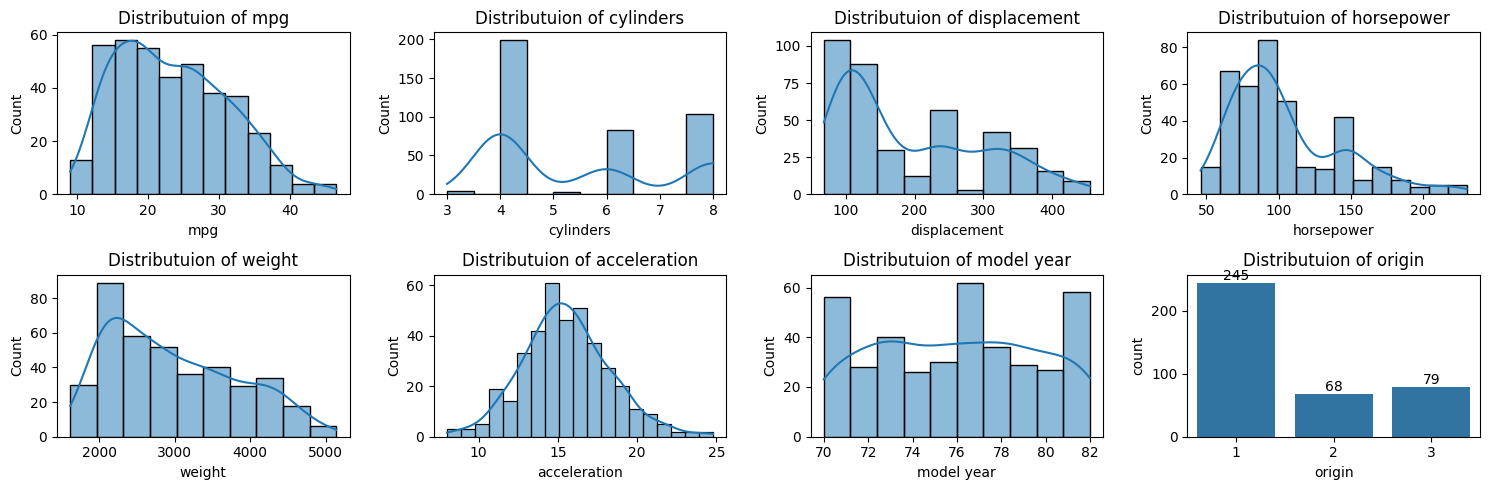

In [23]:
import seaborn as sns
import matplotlib.pyplot as plt

_, axes = plt.subplots(2, 4, figsize=(15, 5))


for i, col in enumerate(data.columns[:-1]):
    if col in quan_var:
        sns.histplot(data, x=col, ax=axes[i//4, i%4], kde=True)
    else:
        sns.countplot(data, x=col, ax=axes[i//4, i%4])
        axes[i//4, i%4].bar_label(axes[i//4, i%4].containers[0])
    axes[i//4, i%4].set_title(f'Distributuion of {col}')
plt.tight_layout()
plt.show()

In [24]:
data.duplicated().sum()

np.int64(0)

In [25]:
data.isna().sum()

mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model year      0
origin          0
car name        0
dtype: int64

**B. Bivariate Analysis**

- Plot pairplot between quantitative columns. Take note on the most potential predictors for the target `MPG`.
- Is `origin` useful for predicting the target `MPG`?
- Preprocess the inputs for model development.

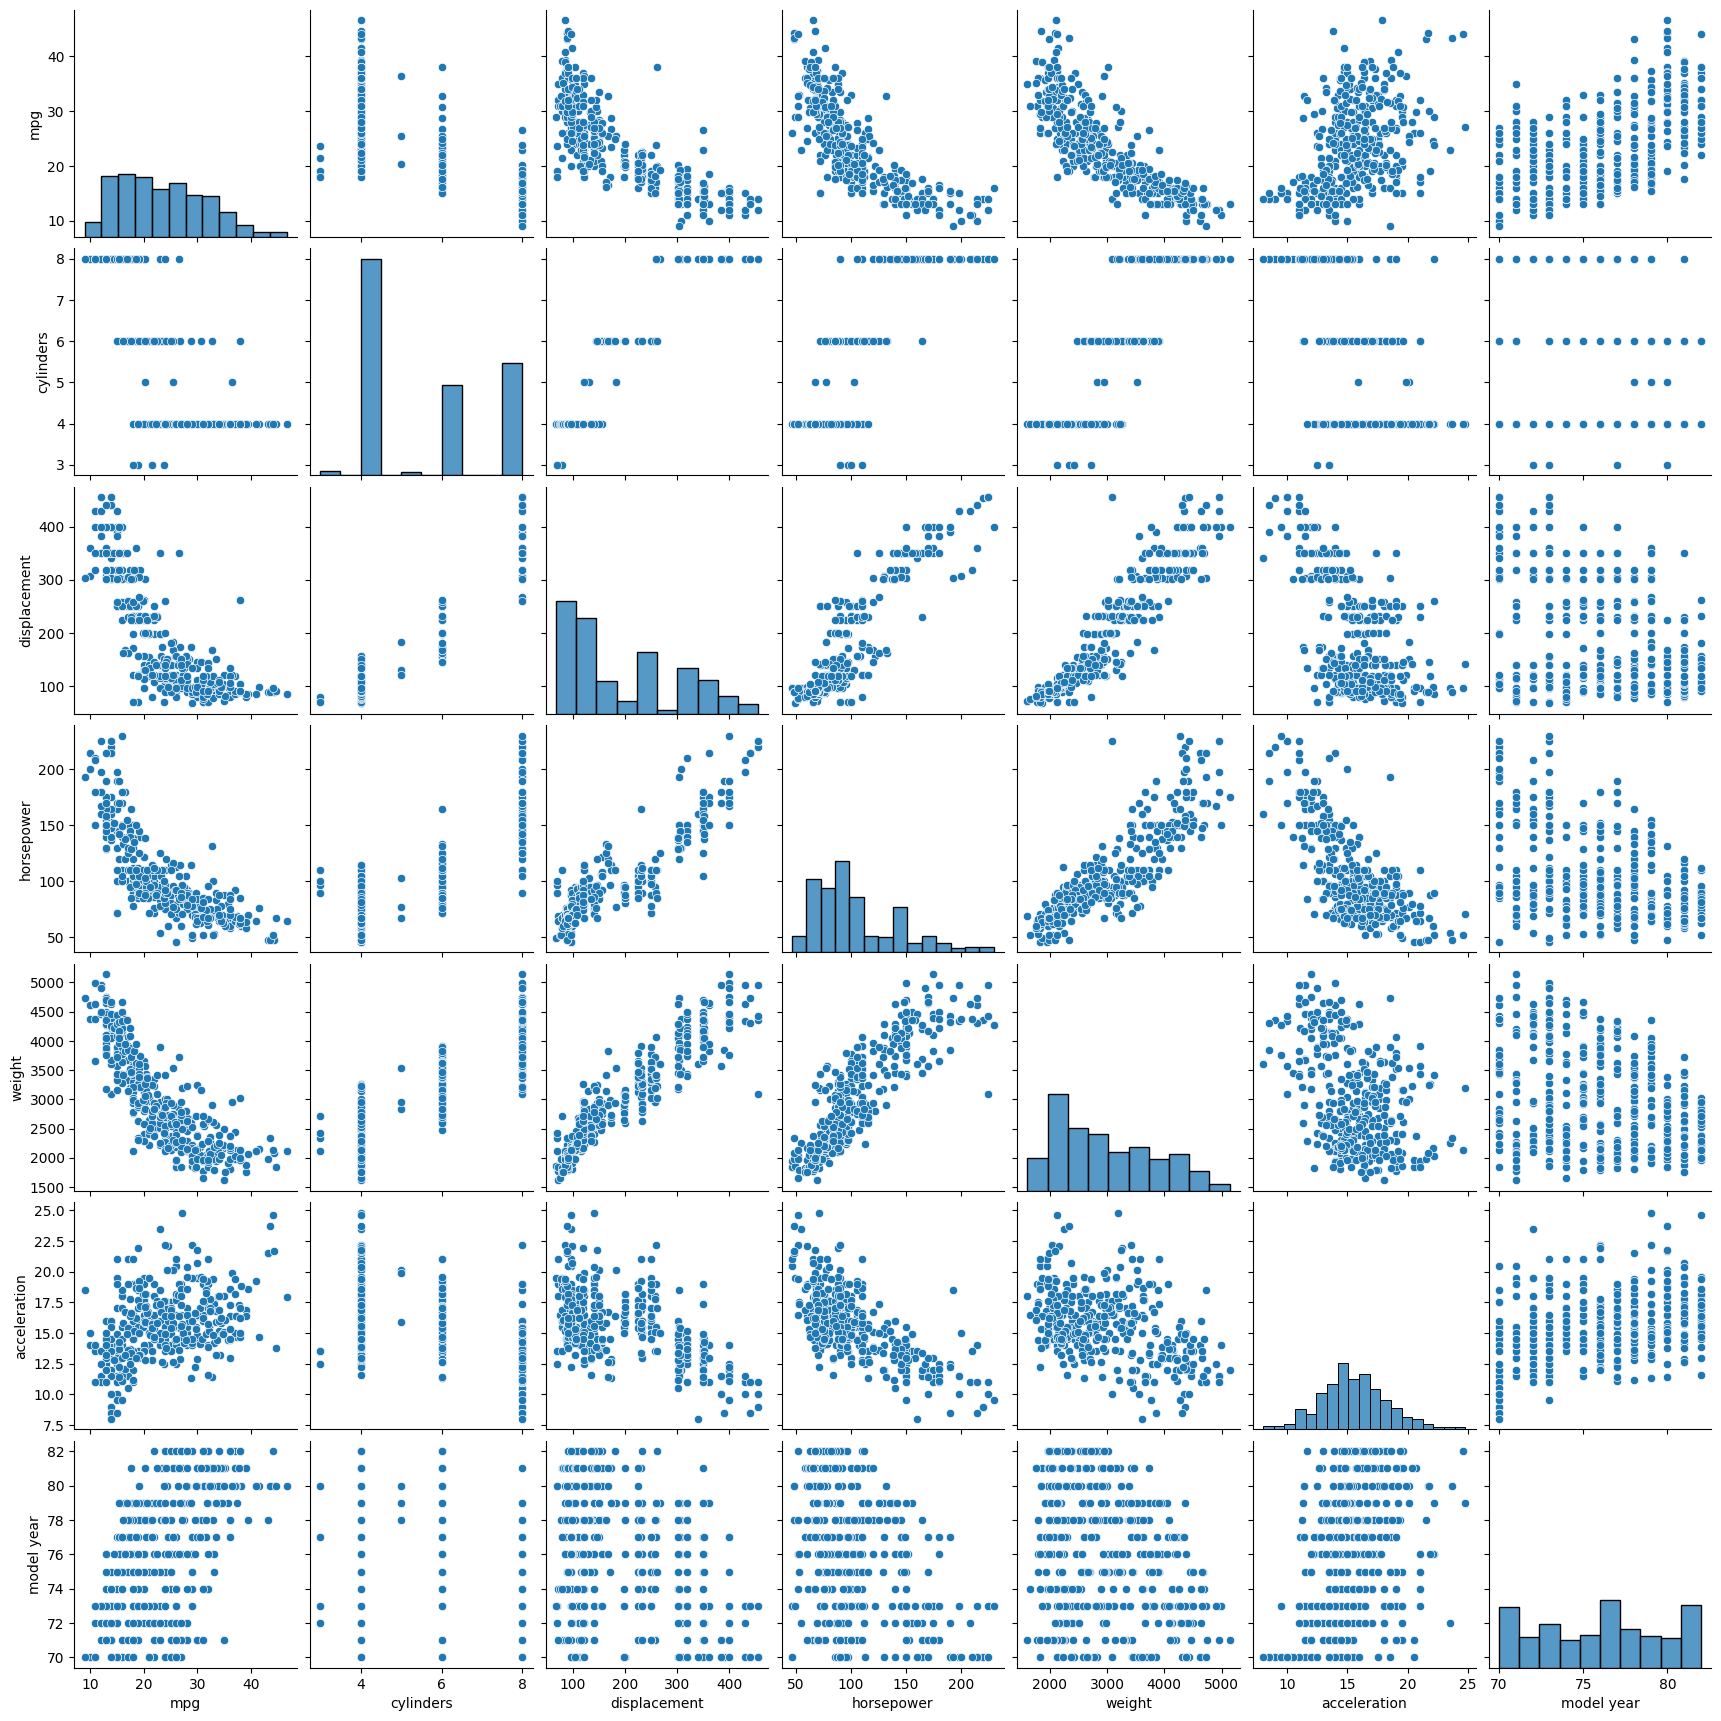

In [36]:
sns.pairplot(data.drop(columns=['origin']))

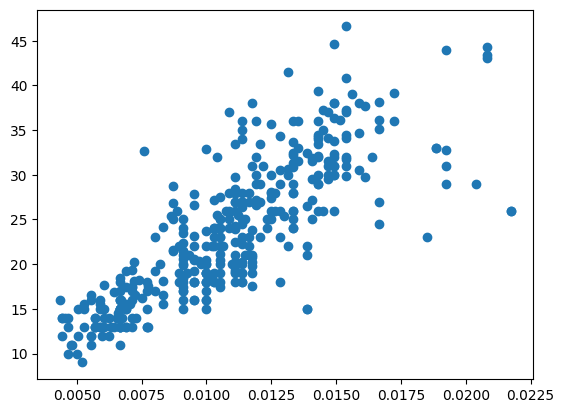

In [29]:
plt.scatter(1/data['horsepower'], data['mpg'])

<Axes: xlabel='origin', ylabel='mpg'>

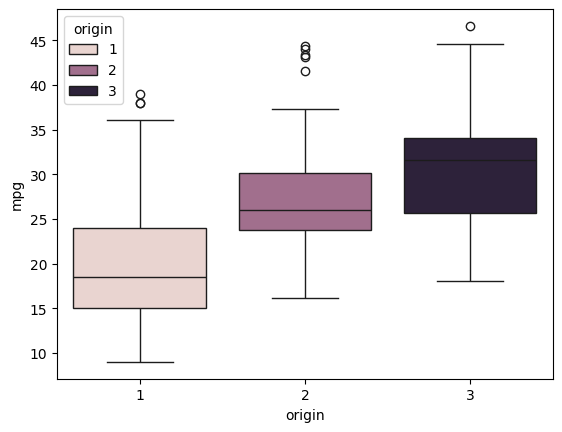

In [35]:
sns.boxplot(data, x='origin', y='mpg', hue='origin')

- Most of the inputs are very useful but required some transformation or feature engineering to boost their predictive power on the target `MPG`.
- `Origin` is clearly important for predicting `MPG`, therefore should be encoded using `one-hot` encoding.
- There are also many highly correlated columns suggesting redundant information which should not be included together in the model.
- `Cylinder` is a quantitative column but with very few distinct values, therefore may be considered `qualitative` instead of `quantitative`. Here, it seemsn to be a negative correlation between `MPG` and `Cylinders` except for cars with 3 cylinders. This rather suggests that it may be better to treat cylinder as categorical data.

In [40]:
data_encoded = pd.get_dummies(data.drop(columns=['car name']), columns=['origin', 'cylinders'], drop_first=True) * 1
data_encoded.head()

,mpg,displacement,horsepower,weight,acceleration,model year,origin_2,origin_3,cylinders_4,cylinders_5,cylinders_6,cylinders_8
0,18.0,307.0,130,3504,12.0,70,0,0,0,0,0,1
1,15.0,350.0,165,3693,11.5,70,0,0,0,0,0,1
2,18.0,318.0,150,3436,11.0,70,0,0,0,0,0,1
3,16.0,304.0,150,3433,12.0,70,0,0,0,0,0,1
4,17.0,302.0,140,3449,10.5,70,0,0,0,0,0,1


**C. Random Forest: OOB vs Cross Validation** 

- Split the dataset into $80\%-20\%$ training-testing data using `random_state = 42`.

- Build a random forest model with its default setting. Then compute the free **Out-Of-Bag Errors** or Score obtained by the forest (see `model.oob_score_`). Compute suitable metrics on the test data and store them in a data frame.

- Fine-tune the key hyperparameters of the random forest (`max_depth`, `max_features`, `n_estimators`...), then evaluate its CV error or Score. Compare it to the corresponding **OOB** criterion for each combination of the hyperparameters. In order to achieve this, you should follow the following steps:
    1. **Initialize:** Ensure you set `oob_score=True` when initializing your `RandomForestRegressor`.
    - **OOB Error:** After fitting the model, access the **OOB** score using the `.oob_score_` attribute of the fitted model object. Convert this to an error rate (e.g., 1−score).
    2. **CV Error:** For the same model configuration, calculate the mean cross-validation score using the `cross_val_score` function (or `cross_validate`) with `k=5` folds. Convert the mean score to an error rate.
    3. **Visualize:** Plot the **OOB Error** and the **CV Error** on the same graph for each hyperparameter. Analyze the gap between the two lines.

- Compare the test metrics of the three models:
    - The default random forest (second point).
    - The model with the best `OOB` performance.
    - The model with the best `CV` performance.

- Compote and plot the figure of `mean decrease impurity measure` and `permutation feature importances` of the last two models.

In [3]:
# To do

**D. Extra-trees: OOB vs Cross Validation** 

- Repeat the previous questions of part **(C)** from the second point using ExtraTrees model from the same module. Compare the result to Random Forest.

- Compote and plot the figure of `mean decrease impurity measure` and `permutation feature importances` of the last two Extra-tree models.

In [ ]:
# To do

**E. XGBoost: OOB vs Cross Validation**

- Repeat the previous quesions with [`XGboost`](https://xgboost.readthedocs.io/en/stable/python/python_intro.html#install-xgboost). 

- Compute and draw both feature importances for the last two XGBoost models.

In [ ]:
# To do

**F. GradientCOBRA: Find-tune the hyperparameter $h$**

- Build `GradientCOBRA` model by fine-tune the most suitable smoothing hyperparameter $h>0$. 
- Compute its test performance and compare the previous models.

In [3]:
# To do

## **2. [Kaggle Cybersecurity Intrusion Detection Dataset](https://www.kaggle.com/datasets/dnkumars/cybersecurity-intrusion-detection-dataset/data){target='_blank'}**

This [Kaggle Cybersecurity Intrusion Detection Dataset](https://www.kaggle.com/datasets/dnkumars/cybersecurity-intrusion-detection-dataset/data){target='_blank'} is designed for detecting cyber intrusions based on network traffic and user behavior. You may find the explanation of the dataset in detail, including the dataset structure, feature importance, possible analysis approaches, and how it can be used for machine learning in the the provided link. 

**Question:** import the dataset, analyze the data and preprocess it properly. Build your best model to detect intrusion activities in the dataset. Report the test performance and features the seem to influence the performance of the model the most.

In [2]:
# To do

# References

$^{\text{📚}}$ [Bagging predictors, Breiman (1996)](https://link.springer.com/article/10.1007/BF00058655){target="_blank"}. <br>
$^{\text{📚}}$ [The strength of weak learnability, Robert E. Schapire (1990).](https://link.springer.com/article/10.1007/BF00116037){target="_blank"}. <br>
$^{\text{📚}}$ [COBRA: A combined regression strategy, Beau et al. (2016)](https://www.sciencedirect.com/science/article/pii/S0047259X15000950){target="_blank"}. <br>
$^{\text{📚}}$ [Gradient COBRA: A kernel-based consensual aggregation for regression, Has (2023)](https://doi.org/10.52933/jdssv.v3i2.70){target="_blank"}. <br>
$^{\text{📚}}$ [Aggregation using input–output trade-off, Fischer & Mougeot (2019)](https://www.sciencedirect.com/science/article/abs/pii/S0378375818302349){target="_blank"}. <br>
$^{\text{📚}}$ [Super Learner, M. J. Van der Laan (2007)](https://www.degruyter.com/document/doi/10.2202/1544-6115.1309/html){target="_blank"}. <br>